# Preliminary SOH Health Classification Analysis — Cell 2_009

**Shraddhaben Patel** — health categories, class balance, and classification models (DATA 245, Group 9)

This notebook prepares the battery-health **classification** part of the project using the pilot feature table created from `2_009.h5`. It defines health categories from the preliminary SOH proxy, checks class balance, and evaluates logistic regression, a decision tree, and a random forest classifier with accuracy, precision, recall, F1-score, and a confusion matrix.

> **Important limitation:** The SOH target (`soh_proxy_percent`) is a preliminary proxy and has not been validated. This notebook uses one battery cell and a random train/test split. It is **not** the final unseen-cell or unseen-profile evaluation. If a class has too few observations, the notebook stops before training and reports that classification is not yet feasible. It does not invent results.

In [10]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report)

RANDOM_STATE = 42
DATA_PATH = Path("pilot_features_2_009.csv")
if not DATA_PATH.exists():
    candidates = list(Path(".").glob("**/pilot_features_2_009.csv"))
    if candidates:
        DATA_PATH = candidates[0]
    else:
        raise FileNotFoundError("Place pilot_features_2_009.csv in the notebook folder.")

df = pd.read_csv(DATA_PATH)
print(f"Loaded {df.shape[0]} rows and {df.shape[1]} columns from {DATA_PATH}")
df.head()

Loaded 57 rows and 22 columns from pilot_features_2_009.csv


,test_group,cell_id,idtest,idexp,experiment,start_datetime,schedule_file,n_measurements,duration_seconds,voltage_mean,...,current_mean,current_min,current_max,temperature_mean_clean,temperature_min_clean,temperature_max_clean,charge_capacity_max,discharge_capacity_max,capacity_estimate,soh_proxy_percent
0,test_0000,2_009,0,44,RTP05,42696.62,RTP_highCurrent,2572,56713.056993,3.852552,...,0.086933,-5.000830,1.529133,6.749401,5.939353,7.920774,2.708039,4.090233,4.090233,100.000000
1,test_0001,2_009,1,44,RTP05,42697.44,RTP,98382,211031.638884,3.765550,...,0.192775,-5.000236,4.333625,7.587502,5.786475,24.720688,2.931648,2.941290,2.941290,71.910085
2,test_0002,2_009,3,46,RTP25,42702.67,RTP_highCurrent,80923,225321.397030,3.786424,...,0.194173,-4.999689,4.536012,19.472317,16.494024,31.513239,3.009906,3.023505,3.023505,73.920119
3,test_0003,2_009,4,47,RTP35,42705.33,RTP_highCurrent,80872,222658.891498,3.771105,...,0.217947,-5.000090,4.720940,26.294689,24.922510,41.217407,3.159502,3.161557,3.161557,77.295292
4,test_0004,2_009,5,48,RTP45,42708.01,RTP_highCurrent,80966,221376.693155,3.768041,...,0.235386,-4.999724,4.840817,36.076683,28.819719,48.293507,3.232599,3.231497,3.231497,79.005198


## 1. Define the target and the health categories

The target is `soh_proxy_percent`. For this preliminary version, two categories are used:

* **Healthy:** SOH proxy ≥ 80%
* **Degraded:** SOH proxy < 80%

The 80% cutoff is the end-of-life point used in our project proposal. A third category, *end-of-life risk*, is **planned** for later, once the SOH target is validated and more cells are available.

SOH proxy summary (%):
count     57.00
mean      65.46
std       10.87
min       20.13
25%       58.42
50%       67.41
75%       72.17
max      100.00


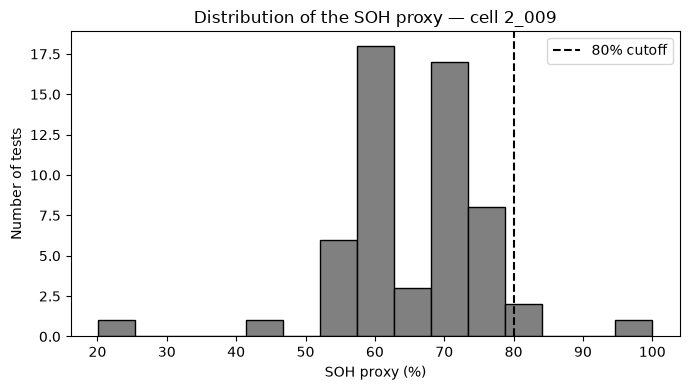

In [11]:
TARGET = "soh_proxy_percent"
THRESHOLD = 80.0          # Healthy: SOH >= 80, Degraded: SOH < 80

df = df.dropna(subset=[TARGET]).copy()
df["health_class"] = np.where(df[TARGET] >= THRESHOLD, "Healthy", "Degraded")

print("SOH proxy summary (%):")
print(df[TARGET].describe().round(2).to_string())

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(df[TARGET], bins=15, color="gray", edgecolor="black")
ax.axvline(THRESHOLD, color="black", linestyle="--", label=f"{THRESHOLD:.0f}% cutoff")
ax.set_xlabel("SOH proxy (%)")
ax.set_ylabel("Number of tests")
ax.set_title("Distribution of the SOH proxy — cell 2_009")
ax.legend()
plt.tight_layout()
plt.savefig("soh_distribution_2_009.png", dpi=200)
plt.show()

## 2. Check class balance

A classifier needs enough examples of every class. Here a class is treated as **too small** if it has fewer than 5 rows. If so, classification is labelled *planned / not yet feasible* and the models are not trained.

In [12]:
MIN_PER_CLASS = 5
class_order = ["Healthy", "Degraded"]

counts = df["health_class"].value_counts().reindex(class_order).fillna(0).astype(int)
class_table = pd.DataFrame({
    "Class": class_order,
    "Rule": [f"SOH proxy >= {THRESHOLD:.0f}%", f"SOH proxy < {THRESHOLD:.0f}%"],
    "Observations": counts.values,
    "Share of rows (%)": (counts.values / counts.sum() * 100).round(1)
})
class_table.to_csv("class_counts_2_009.csv", index=False)
display(class_table)

print("\nExploratory counts at other cutoffs (for discussion only, not used as results):")
other = pd.DataFrame({
    "Cutoff (SOH proxy >=)": [60, 70, 75, 80, 85, 90],
})
other["Healthy"] = [(df[TARGET] >= t).sum() for t in other["Cutoff (SOH proxy >=)"]]
other["Degraded"] = [(df[TARGET] < t).sum() for t in other["Cutoff (SOH proxy >=)"]]
display(other)

feasible = counts.min() >= MIN_PER_CLASS
if feasible:
    print("\nStatus: each class has at least", MIN_PER_CLASS, "rows. Classification can be tried.")
else:
    print("\nStatus: NOT FEASIBLE YET. A class has fewer than", MIN_PER_CLASS, "rows.")
    print("Classification is therefore PLANNED / PRELIMINARY. It will be completed after the SOH target")
    print("is validated and more cells are processed. No classification results are reported.")

,Class,Rule,Observations,Share of rows (%)
0,Healthy,SOH proxy >= 80%,1,1.8
1,Degraded,SOH proxy < 80%,56,98.2



Exploratory counts at other cutoffs (for discussion only, not used as results):


,Cutoff (SOH proxy >=),Healthy,Degraded
0,60,35,22
1,70,24,33
2,75,6,51
3,80,1,56
4,85,1,56
5,90,1,56



Status: NOT FEASIBLE YET. A class has fewer than 5 rows.
Classification is therefore PLANNED / PRELIMINARY. It will be completed after the SOH target
is validated and more cells are processed. No classification results are reported.


## 3. Select input features

Columns that must **not** be used as inputs:

* **Capacity-derived columns** (`capacity_estimate`, `charge_capacity_max`, `discharge_capacity_max`): the SOH proxy is calculated from capacity, so they would leak the answer into the model.
* **Identifier and text columns** (`test_group`, `cell_id`, `experiment`, `schedule_file`): names and labels, not measurements.
* **Order-of-testing columns** (`idtest`, `idexp`, `start_datetime`): these track *when* a test happened, which follows the aging order. They could let a model infer the health class from the test order instead of from battery measurements.

In [13]:
EXCLUDED = {
    TARGET, "health_class",
    "capacity_estimate", "charge_capacity_max", "discharge_capacity_max",
    "test_group", "cell_id", "experiment", "schedule_file",
    "idtest", "idexp", "start_datetime"
}
feature_columns = [c for c in df.columns
                   if c not in EXCLUDED and pd.api.types.is_numeric_dtype(df[c])]
X = df[feature_columns].copy()
y = df["health_class"].copy()

print("Features used:", feature_columns)
print("Rows:", len(X))
print("Missing values per feature:")
print(X.isna().sum()[X.isna().sum() > 0].to_string() or "none")
X.describe().T

Features used: ['n_measurements', 'duration_seconds', 'voltage_mean', 'voltage_min', 'voltage_max', 'current_mean', 'current_min', 'current_max', 'temperature_mean_clean', 'temperature_min_clean', 'temperature_max_clean']
Rows: 57
Missing values per feature:
temperature_mean_clean    1
temperature_min_clean     1
temperature_max_clean     1


,count,mean,std,min,25%,50%,75%,max
n_measurements,57.0,240110.631579,237907.807346,51.000000,79080.000000,80923.000000,4.857610e+05,7.040620e+05
duration_seconds,57.0,747897.206948,770064.518761,3591.123468,222004.914778,224205.520537,1.556903e+06,2.235112e+06
voltage_mean,57.0,3.573486,0.236040,3.285869,3.292933,3.767025,3.773834e+00,3.852552e+00
voltage_min,57.0,2.724730,0.282035,2.275153,2.499728,2.499890,2.933473e+00,3.586603e+00
voltage_max,57.0,4.169308,0.049312,3.947544,4.154606,4.200170,4.200981e+00,4.259114e+00
current_mean,57.0,-1.688524,2.189897,-4.611829,-4.178306,0.159402,1.951918e-01,7.131314e-01
current_min,57.0,-6.442749,2.214940,-9.829071,-8.871021,-5.001148,-5.000225e+00,0.000000e+00
current_max,57.0,3.022129,1.571567,0.000000,1.626352,4.117391,4.424088e+00,5.333874e+00
temperature_mean_clean,56.0,34.357122,9.926587,6.749401,27.608885,29.516984,4.381497e+01,4.759367e+01
temperature_min_clean,56.0,32.018320,9.343525,5.786475,26.572054,28.328124,4.095676e+01,4.523153e+01


## 4. Create the pilot split

An 80/20 random split with random state 42 is used, the same settings as the regression pilot. The split is stratified (it keeps the class proportions) whenever every class has at least 2 rows. The final project will also use cell-held-out and profile-held-out splits.

In [14]:
strat = y if y.value_counts().min() >= 2 else None
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=strat
)
print("Stratified split:", strat is not None)
print("Training rows:", len(X_train), "| class counts:", y_train.value_counts().to_dict())
print("Testing rows: ", len(X_test), "| class counts:", y_test.value_counts().to_dict())

can_train = feasible and y_train.nunique() == 2
if not can_train:
    print("\nThe training set does not contain both classes (or a class is too small).")
    print("The classification models are NOT trained in this notebook run.")

Stratified split: False
Training rows: 45 | class counts: {'Degraded': 45}
Testing rows:  12 | class counts: {'Degraded': 11, 'Healthy': 1}

The training set does not contain both classes (or a class is too small).
The classification models are NOT trained in this notebook run.


## 5. Train the classification models and evaluate them

Models (trained only if classification is feasible):

* **Logistic regression** (with scaling and balanced class weights)
* **Decision tree** (maximum depth 3, balanced class weights)
* **Random forest classifier** (200 trees, balanced class weights)

Metrics: accuracy, precision, recall, F1-score for each class, and a confusion matrix. Recall for the **Degraded** and **end-of-life-risk** side matters most, because missing a battery near the end of its life is the costly mistake.

In [15]:
def make_models():
    return {
        "Logistic regression": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE))
        ]),
        "Decision tree": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=RANDOM_STATE))
        ]),
        "Random forest": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestClassifier(n_estimators=200, class_weight="balanced",
                                             random_state=RANDOM_STATE, n_jobs=-1))
        ]),
    }

def evaluate_models(X_train, X_test, y_train, y_test, tag):
    models = make_models()
    rows, fitted = [], {}
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
    for ax, (name, model) in zip(axes, models.items()):
        model.fit(X_train, y_train)
        pred = model.predict(X_test)
        fitted[name] = model
        p, r, f, _ = precision_recall_fscore_support(y_test, pred, labels=class_order, zero_division=0)
        rows.append({"Model": name, "Accuracy": accuracy_score(y_test, pred),
                     "Precision (Healthy)": p[0], "Recall (Healthy)": r[0], "F1 (Healthy)": f[0],
                     "Precision (Degraded)": p[1], "Recall (Degraded)": r[1], "F1 (Degraded)": f[1]})
        print(f"=== {name} ===")
        print(classification_report(y_test, pred, labels=class_order, zero_division=0))
        cm = confusion_matrix(y_test, pred, labels=class_order)
        ax.imshow(cm, cmap="Greys")
        ax.set_xticks([0, 1]); ax.set_xticklabels(class_order)
        ax.set_yticks([0, 1]); ax.set_yticklabels(class_order)
        for i in range(2):
            for j in range(2):
                ax.text(j, i, cm[i, j], ha="center", va="center", color="red", fontsize=14)
        ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(name)
    plt.tight_layout()
    plt.savefig(f"confusion_matrices_{tag}.png", dpi=200)
    plt.show()
    res = pd.DataFrame(rows).round(3)
    res.to_csv(f"classification_results_{tag}.csv", index=False)
    return res, fitted

if can_train:
    results_df, fitted_models = evaluate_models(X_train, X_test, y_train, y_test, "2_009")
    display(results_df)
else:
    print("Skipped: classification is planned / not yet feasible on this table.")
    with open("classification_status_2_009.txt", "w") as f:
        f.write("Classification not feasible on the pilot table: a class has fewer than "
                f"{MIN_PER_CLASS} rows. Class counts: {counts.to_dict()}.\n")
    print("Saved classification_status_2_009.txt")

Skipped: classification is planned / not yet feasible on this table.
Saved classification_status_2_009.txt


## 6. Feature interpretation

When models have been trained, this section shows which features help classify battery health: random forest feature importance, and logistic regression coefficients (on scaled features). It is skipped when classification is not feasible.

In [16]:
def interpret(fitted, features, tag):
    rf = fitted["Random forest"].named_steps["model"]
    imp = pd.Series(rf.feature_importances_, index=features).sort_values()
    fig, ax = plt.subplots(figsize=(7, 0.4 * len(imp) + 1.5))
    imp.plot.barh(ax=ax, color="black")
    ax.set_xlabel("Importance"); ax.set_title("Random forest feature importance (preliminary)")
    plt.tight_layout(); plt.savefig(f"feature_importance_{tag}.png", dpi=200); plt.show()
    lr = fitted["Logistic regression"].named_steps["model"]
    coef = pd.Series(lr.coef_[0], index=features).sort_values()
    display(coef.round(3).to_frame("Logistic regression coefficient"))

if can_train:
    interpret(fitted_models, feature_columns, "2_009")
else:
    print("Skipped: feature interpretation will be done after the classes are usable.")

Skipped: feature interpretation will be done after the classes are usable.


## 7. Optional pipeline check (exploratory only)

By default this section does nothing (`RUN_EXPLORATORY = False`). If you turn it on, it runs the same code with a **different cutoff** only to check that the pipeline works when both classes are present. Those numbers are **not results**: choosing a cutoff to balance the classes on an unvalidated SOH proxy would be arbitrary, and the report does not use them.

In [17]:
RUN_EXPLORATORY = False
EXPLORATORY_THRESHOLD = 70.0

if RUN_EXPLORATORY:
    d2 = df.copy()
    d2["health_class"] = np.where(d2[TARGET] >= EXPLORATORY_THRESHOLD, "Healthy", "Degraded")
    y2 = d2["health_class"]
    print("Exploratory class counts:", y2.value_counts().to_dict())
    if y2.value_counts().min() >= 2:
        a, b, c, d = train_test_split(X, y2, test_size=0.20, random_state=RANDOM_STATE, stratify=y2)
        res2, _ = evaluate_models(a, b, c, d, "exploratory_70")
        display(res2)
        print("EXPLORATORY ONLY: do not report these numbers as results.")
else:
    print("Exploratory check is switched off.")

Exploratory check is switched off.


## 8. Report interpretation

On the pilot table, the classes are heavily unbalanced at the 80% cutoff, so classification is **planned / preliminary** and no performance numbers are reported. The SOH proxy also depends on the type of test, because the pilot file mixes several experiment types and test lengths, so any health class built on it must be treated as preliminary.

Remaining work: finalize the SOH threshold once the SOH target is validated, check class balance on the multi-cell table, run the classification models, test unseen-cell and unseen-profile performance, and interpret the important features.

## 9. Reproducibility details

* Data: `2_009.h5`, represented by `pilot_features_2_009.csv`
* Target: `soh_proxy_percent`
* Categories: Healthy (SOH proxy ≥ 80%) and Degraded (< 80%); end-of-life risk is planned
* Minimum rows per class: 5
* Split: 80% training and 20% testing, random state 42 (stratified when possible)
* Logistic regression: scaling, balanced class weights, max_iter = 1000
* Decision tree: maximum depth 3, balanced class weights
* Random forest: 200 trees, balanced class weights, random state 42
* Metrics: accuracy, precision, recall, F1-score, confusion matrix

Output files created by this notebook: `class_counts_2_009.csv`, `soh_distribution_2_009.png`, and either `classification_status_2_009.txt` (when classification is not feasible) or `classification_results_2_009.csv`, `confusion_matrices_2_009.png`, and `feature_importance_2_009.png`.